In [1]:
!pip install nltk pandas matplotlib seaborn pyspellchecker scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.2/7.2 MB 29.6 MB/s eta 0:00:00


In [2]:
import nltk

nltk.download('gutenberg')
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')

[nltk_data] Downloading package gutenberg to /root/nltk_data...
[nltk_data]   Unzipping corpora/gutenberg.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [3]:
from nltk.corpus import gutenberg

books = gutenberg.fileids()

print("Total books:", len(books))
print("Available books:", books[:10])

text = " ".join(gutenberg.raw(book) for book in books)

print("Total characters:", len(text))
print(text[:500])

Total books: 18
Available books: ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt']
Total characters: 11793335
[Emma by Jane Austen 1816]

VOLUME I

CHAPTER I


Emma Woodhouse, handsome, clever, and rich, with a comfortable home
and happy disposition, seemed to unite some of the best blessings
of existence; and had lived nearly twenty-one years in the world
with very little to distress or vex her.

She was the youngest of the two daughters of a most affectionate,
indulgent father; and had, in consequence of her sister's marriage,
been mistress of his house from a very early period.  Her mother
had died t


In [4]:
from nltk.corpus import gutenberg

book_ids = gutenberg.fileids()

print("Total books:", len(book_ids))
print("Available books:", book_ids[:10])

raw_text = " ".join(
    gutenberg.raw(book_id) for book_id in book_ids
)

print("Total characters:", len(raw_text))
print(raw_text[:500])

Total books: 18
Available books: ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt']
Total characters: 11793335
[Emma by Jane Austen 1816]

VOLUME I

CHAPTER I


Emma Woodhouse, handsome, clever, and rich, with a comfortable home
and happy disposition, seemed to unite some of the best blessings
of existence; and had lived nearly twenty-one years in the world
with very little to distress or vex her.

She was the youngest of the two daughters of a most affectionate,
indulgent father; and had, in consequence of her sister's marriage,
been mistress of his house from a very early period.  Her mother
had died t


In [5]:
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

from collections import Counter, defaultdict
from nltk.corpus import stopwords
from nltk.util import ngrams

text = raw_text.lower()

# Extract words and remove punctuation/numbers
tokens = re.findall(r"\b[a-z]+\b", text)

stop_words = set(stopwords.words("english"))

cleaned_tokens = [
    word for word in tokens
    if word not in stop_words and len(word) > 1
]

print("Original tokens:", len(tokens))
print("Cleaned tokens:", len(cleaned_tokens))
print("Sample:", cleaned_tokens[:30])

Original tokens: 2135393
Cleaned tokens: 1025030
Sample: ['emma', 'jane', 'austen', 'volume', 'chapter', 'emma', 'woodhouse', 'handsome', 'clever', 'rich', 'comfortable', 'home', 'happy', 'disposition', 'seemed', 'unite', 'best', 'blessings', 'existence', 'lived', 'nearly', 'twenty', 'one', 'years', 'world', 'little', 'distress', 'vex', 'youngest', 'two']


,Word,Frequency
0,shall,11682
1,said,9429
2,unto,9010
3,lord,8590
4,thou,6759
5,one,6218
6,man,5615
7,thy,5609
8,god,5287
9,thee,4807


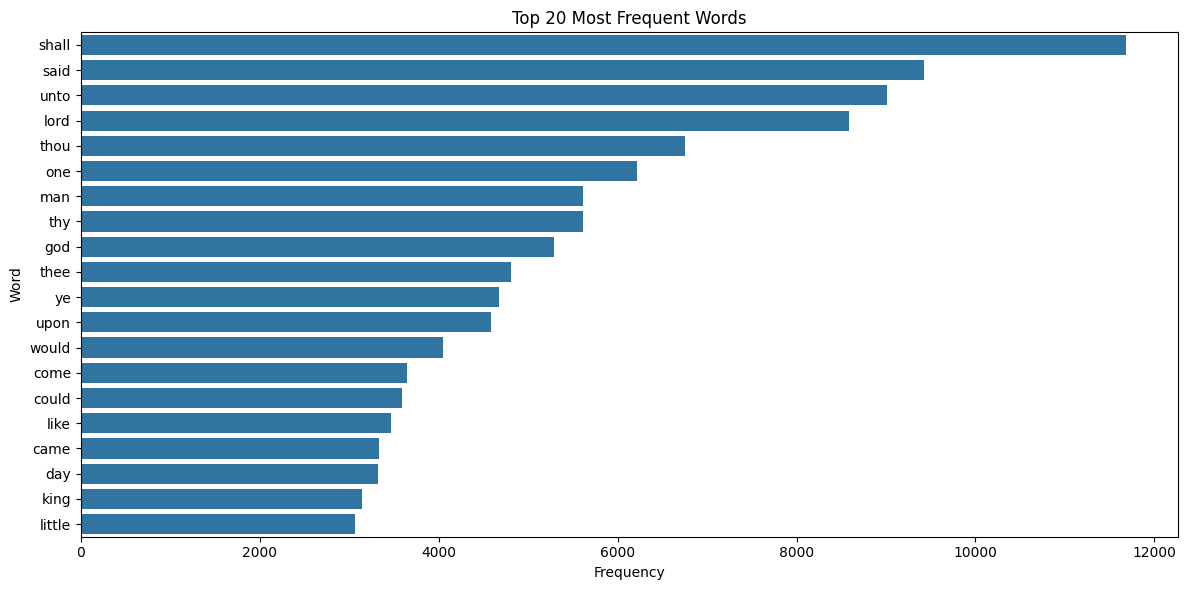

In [6]:
word_counts = Counter(cleaned_tokens)

frequency_df = pd.DataFrame(
    word_counts.most_common(20),
    columns=["Word", "Frequency"]
)

display(frequency_df)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=frequency_df,
    x="Frequency",
    y="Word"
)

plt.title("Top 20 Most Frequent Words")
plt.tight_layout()
plt.show()

In [7]:
# 90% training data, 10% testing data
split_index = int(len(tokens) * 0.90)

train_tokens = tokens[:split_index]
test_tokens = tokens[split_index:]

# Bigram model
bigram_counts = defaultdict(Counter)

for previous, next_word in zip(
    train_tokens[:-1],
    train_tokens[1:]
):
    bigram_counts[previous][next_word] += 1

# Trigram model
trigram_counts = defaultdict(Counter)

for i in range(len(train_tokens) - 2):
    context = (train_tokens[i], train_tokens[i + 1])
    next_word = train_tokens[i + 2]
    trigram_counts[context][next_word] += 1

print("Training words:", len(train_tokens))
print("Testing words:", len(test_tokens))
print("Bigram contexts:", len(bigram_counts))
print("Trigram contexts:", len(trigram_counts))

Training words: 1921853
Testing words: 213540
Bigram contexts: 34619
Trigram contexts: 497171


In [8]:
def predict_bigram(prefix, top_n=3):
    words = prefix.lower().split()

    if not words:
        return []

    candidates = bigram_counts.get(words[-1], Counter())
    return candidates.most_common(top_n)


def predict_trigram(prefix, top_n=3):
    words = prefix.lower().split()

    if not words:
        return []

    if len(words) >= 2:
        context = (words[-2], words[-1])
        candidates = trigram_counts.get(context, Counter())

        if candidates:
            return candidates.most_common(top_n)

    # Fallback if trigram context is unavailable
    return predict_bigram(prefix, top_n)


print("Bigram:", predict_bigram("in the"))
print("Trigram:", predict_trigram("in the"))

Bigram: [('lord', 7071), ('king', 1852), ('son', 1526)]
Trigram: [('land', 333), ('midst', 307), ('world', 238)]


In [9]:
test_prefixes = [
    "the king",
    "in the",
    "she was",
    "it is",
    "he said",
    "there was",
    "i am",
    "of the",
    "and the",
    "once upon"
]

prediction_rows = []

for prefix in test_prefixes:
    bigram_predictions = predict_bigram(prefix)
    trigram_predictions = predict_trigram(prefix)

    prediction_rows.append({
        "Input Prefix": prefix,
        "Bigram Top 3": ", ".join(
            word for word, count in bigram_predictions
        ),
        "Trigram Top 3": ", ".join(
            word for word, count in trigram_predictions
        )
    })

prediction_df = pd.DataFrame(prediction_rows)
display(prediction_df)

,Input Prefix,Bigram Top 3,Trigram Top 3
0,the king,"of, s, and","of, s, and"
1,in the,"lord, king, son","land, midst, world"
2,she was,"a, the, not","not, a, very"
3,it is,"the, a, not","a, not, the"
4,he said,"unto, the, he","unto, i, to"
5,there was,"a, the, not","a, no, not"
6,i am,"sure, the, not","sure, the, not"
7,of the,"lord, king, son","lord, house, children"
8,and the,"lord, king, son","lord, king, children"
9,once upon,"the, his, him",a


In [10]:
def evaluate_autocomplete(model_name, top_n=3, max_samples=5000):
    hits = 0
    total = 0

    # Test data starts at split_index.
    # Use preceding words as context.
    for i in range(split_index, len(tokens) - 1):
        actual_next = tokens[i + 1]

        if model_name == "bigram":
            prefix = tokens[i]
            predictions = predict_bigram(prefix, top_n)
        else:
            prefix = tokens[i - 1] + " " + tokens[i]
            predictions = predict_trigram(prefix, top_n)

        predicted_words = [word for word, count in predictions]

        hits += int(actual_next in predicted_words)
        total += 1

        if total >= max_samples:
            break

    precision_at_k = hits / (total * top_n) if total else 0
    recall_at_k = hits / total if total else 0

    return {
        "Model": model_name,
        "Test Samples": total,
        "Correct Top-3 Hits": hits,
        "Precision@3": precision_at_k,
        "Recall@3": recall_at_k
    }


autocomplete_results = pd.DataFrame([
    evaluate_autocomplete("bigram"),
    evaluate_autocomplete("trigram")
])

display(autocomplete_results.round(4))

,Model,Test Samples,Correct Top-3 Hits,Precision@3,Recall@3
0,bigram,5000,579,0.0386,0.1158
1,trigram,5000,541,0.0361,0.1082


In [11]:
!pip install pyspellchecker

In [12]:
from spellchecker import SpellChecker
from difflib import get_close_matches

spell = SpellChecker()

def autocorrect_spellchecker(word):
    word = word.lower().strip()

    if not word:
        return word

    correction = spell.correction(word)
    return correction if correction is not None else word


typo_pairs = [
    ("recieve", "receive"),
    ("definately", "definitely"),
    ("teh", "the"),
    ("adn", "and"),
    ("wierd", "weird"),
    ("occured", "occurred"),
    ("seperate", "separate"),
    ("untill", "until"),
    ("begining", "beginning"),
    ("enviroment", "environment"),
    ("thier", "their"),
    ("beleive", "believe"),
    ("freind", "friend"),
    ("acheive", "achieve"),
    ("goverment", "government"),
    ("sucess", "success"),
    ("tommorow", "tomorrow"),
    ("knowlege", "knowledge"),
    ("resturant", "restaurant"),
    ("accomodate", "accommodate")
]

correction_rows = []

for typo, expected in typo_pairs:
    predicted = autocorrect_spellchecker(typo)

    correction_rows.append({
        "Misspelled Word": typo,
        "Expected Correction": expected,
        "Predicted Correction": predicted,
        "Correct": predicted == expected
    })

correction_df = pd.DataFrame(correction_rows)
display(correction_df)

,Misspelled Word,Expected Correction,Predicted Correction,Correct
0,recieve,receive,receive,True
1,definately,definitely,definitely,True
2,teh,the,the,True
3,adn,and,and,True
4,wierd,weird,weird,True
5,occured,occurred,occurred,True
6,seperate,separate,separate,True
7,untill,until,until,True
8,begining,beginning,beginning,True
9,enviroment,environment,environment,True


In [13]:
# Candidate words from the corpus and spelling dictionary
vocabulary = set(cleaned_tokens)
vocabulary.update(spell.word_frequency.words())

def autocorrect_difflib(word):
    word = word.lower().strip()

    matches = get_close_matches(
        word,
        list(vocabulary),
        n=1,
        cutoff=0.75
    )

    return matches[0] if matches else word


comparison_rows = []

for typo, expected in typo_pairs:
    py_result = autocorrect_spellchecker(typo)
    diff_result = autocorrect_difflib(typo)

    comparison_rows.append({
        "Misspelled Word": typo,
        "Expected Word": expected,
        "PySpellChecker": py_result,
        "PySpellChecker Correct": py_result == expected,
        "Difflib": diff_result,
        "Difflib Correct": diff_result == expected
    })

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)

print(
    "PySpellChecker accuracy:",
    round(comparison_df["PySpellChecker Correct"].mean(), 3)
)

print(
    "Difflib accuracy:",
    round(comparison_df["Difflib Correct"].mean(), 3)
)

,Misspelled Word,Expected Word,PySpellChecker,PySpellChecker Correct,Difflib,Difflib Correct
0,recieve,receive,receive,True,relieve,False
1,definately,definitely,definitely,True,definitely,True
2,teh,the,the,True,teth,False
3,adn,and,and,True,adn,False
4,wierd,weird,weird,True,wrier,False
5,occured,occurred,occurred,True,occurred,True
6,seperate,separate,separate,True,seperated,False
7,untill,until,until,True,untill,False
8,begining,beginning,beginning,True,beginning,True
9,enviroment,environment,environment,True,environment,True


PySpellChecker accuracy: 1.0
Difflib accuracy: 0.55


,Algorithm,Accuracy
0,PySpellChecker,1.00
1,Difflib,0.55


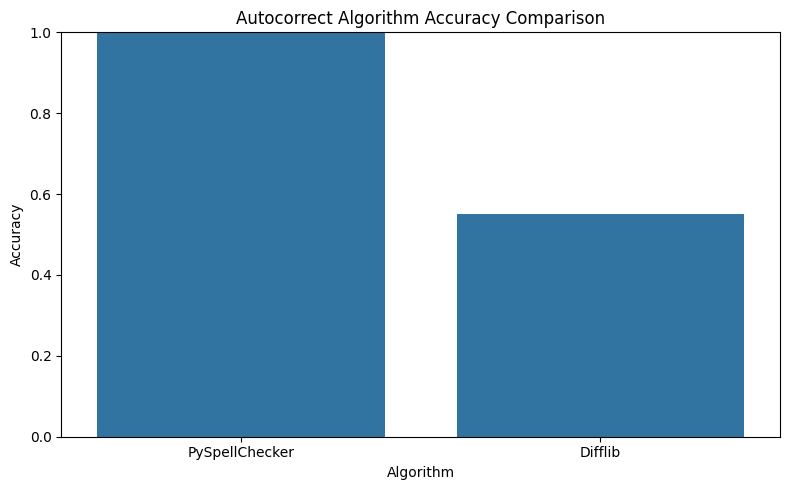

In [14]:
accuracy_df = pd.DataFrame({
    "Algorithm": ["PySpellChecker", "Difflib"],
    "Accuracy": [
        comparison_df["PySpellChecker Correct"].mean(),
        comparison_df["Difflib Correct"].mean()
    ]
})

display(accuracy_df)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=accuracy_df,
    x="Algorithm",
    y="Accuracy"
)

plt.title("Autocorrect Algorithm Accuracy Comparison")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

In [15]:
metric_rows = []

for algorithm, column in [
    ("PySpellChecker", "PySpellChecker Correct"),
    ("Difflib", "Difflib Correct")
]:
    correct = int(comparison_df[column].sum())
    total = len(comparison_df)
    wrong = total - correct

    metric_rows.append({
        "Algorithm": algorithm,
        "Accuracy": correct / total if total else 0,
        "Precision": correct / (correct + wrong) if total else 0,
        "Recall": correct / (correct + wrong) if total else 0
    })

autocorrect_metrics = pd.DataFrame(metric_rows)
display(autocorrect_metrics.round(3))

,Algorithm,Accuracy,Precision,Recall
0,PySpellChecker,1.00,1.00,1.00
1,Difflib,0.55,0.55,0.55


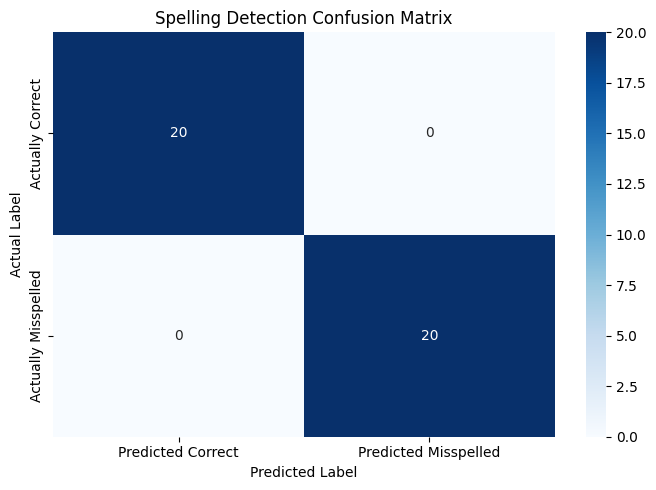

                   precision    recall  f1-score   support

Correctly Spelled       1.00      1.00      1.00        20
       Misspelled       1.00      1.00      1.00        20

         accuracy                           1.00        40
        macro avg       1.00      1.00      1.00        40
     weighted avg       1.00      1.00      1.00        40



In [16]:
from sklearn.metrics import confusion_matrix, classification_report

correct_words = [
    "apple", "house", "water", "school", "friend",
    "beautiful", "computer", "language", "science", "project",
    "people", "important", "because", "morning", "family",
    "student", "python", "analysis", "garden", "music"
]

actual_labels = []
predicted_labels = []

# Label 1 = misspelled; Label 0 = correctly spelled
for typo, expected in typo_pairs:
    actual_labels.append(1)
    predicted_labels.append(
        int(autocorrect_spellchecker(typo) != typo)
    )

for word in correct_words:
    actual_labels.append(0)
    predicted_labels.append(
        int(autocorrect_spellchecker(word) != word)
    )

cm = confusion_matrix(
    actual_labels,
    predicted_labels,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted Correct", "Predicted Misspelled"],
    yticklabels=["Actually Correct", "Actually Misspelled"]
)

plt.title("Spelling Detection Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

print(classification_report(
    actual_labels,
    predicted_labels,
    labels=[0, 1],
    target_names=["Correctly Spelled", "Misspelled"],
    zero_division=0
))

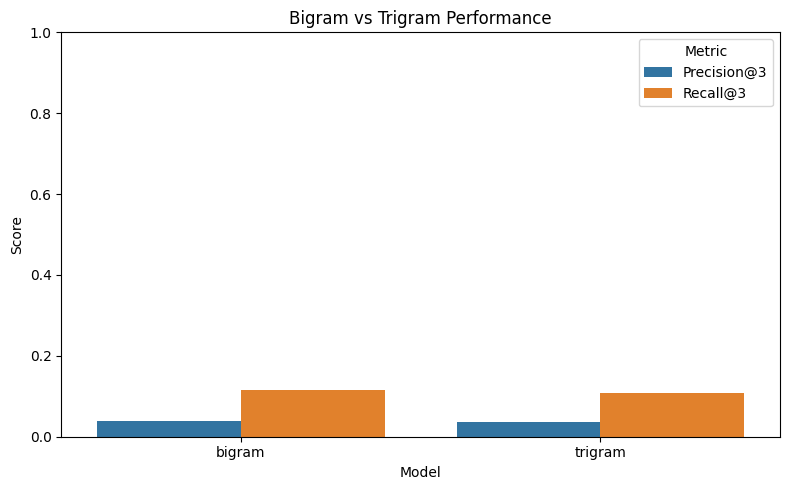

In [17]:
plot_df = autocomplete_results.melt(
    id_vars="Model",
    value_vars=["Precision@3", "Recall@3"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=plot_df,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Bigram vs Trigram Performance")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

In [18]:
frequency_df.to_csv("top_20_words.csv", index=False)
prediction_df.to_csv("autocomplete_predictions.csv", index=False)
autocomplete_results.to_csv("autocomplete_metrics.csv", index=False)
correction_df.to_csv("autocorrect_results.csv", index=False)
comparison_df.to_csv("algorithm_comparison.csv", index=False)
autocorrect_metrics.to_csv("autocorrect_metrics.csv", index=False)

print("All result CSV files saved successfully!")

All result CSV files saved successfully!
